Problema de overtfitting con árboles de decisión

En general los árboles de decisión tienden a tener buen desempeño, a costar de sobreajustar a los datos utilizados, en algunos casos pequeñas variaciones en la estructura y forma de los datos de entrada hace que el desempeño cambie de forma irregular en problemas de clasificación o regresión.

In [4]:
!pip install ucimlrepo

In [99]:
import numpy as np
import matplotlib.pyplot as plt

In [35]:
# Importamos datos de UCI ML repository
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
concrete_compressive_strength = fetch_ucirepo(id=165) 
  
# data (as pandas dataframes) 
X = concrete_compressive_strength.data.features
y = concrete_compressive_strength.data.targets

#### Los datos provienen de la fuerza de comprension de un concreto

In [37]:
# Covariables
X

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360
...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28


y es lo que voy a querer predecir

In [39]:
# respuesta
y

,Concrete compressive strength
0,79.99
1,61.89
2,40.27
3,41.05
4,44.30
...,...
1025,44.28
1026,31.18
1027,23.70
1028,32.77


In [41]:
y.shape

(1030, 1)

In [43]:
len(y)

1030

In [45]:
np.array(y)[2]

array([40.27])

In [47]:
np.array(y)[2][0]

40.27

Entrenemos un árbol de decisión con los datos anteriores

In [49]:
from sklearn.model_selection import train_test_split

X_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.30)

In [51]:
from sklearn.tree import DecisionTreeRegressor

reg_tree = DecisionTreeRegressor(max_depth = 5)
reg_tree.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=5)

In [53]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

y_pred = reg_tree.predict(x_test)

print('R2 Score: ', np.round(r2_score(y_pred, y_test), 2))
print('MAE: ', np.round(mean_absolute_error(y_pred, y_test), 2))
print('MAPE: ', np.round(mean_absolute_percentage_error(y_pred, y_test), 2))

R2 Score:  0.74
MAE:  6.16
MAPE:  0.21


¿Qué ocurre si repetimos este proceso construyendo entrenamientos de testeo y training de forma iterativa?

In [55]:
# Va a repetir el proceso 100 veces.

Ns = 100

r2s = []
mapes = []
maes = []
for i in range(Ns):
    X_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.25)
    reg_tree = DecisionTreeRegressor(max_depth = 5)
    reg_tree.fit(X_train, y_train)

    y_pred = reg_tree.predict(x_test)

    r2s.append(r2_score(y_pred, y_test))
    mapes.append(mean_absolute_percentage_error(y_pred, y_test))
    maes.append(mean_absolute_error(y_pred, y_test))

Repasando lo anterior, pero con Random Forest

In [57]:
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings('ignore')

Ns = 100

r2s_rf = []
mapes_rf = []
maes_rf = []
for i in range(Ns):
    X_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.25)

    # vas a ocupar 100 arboles y le vas a dar la misma profundidad que el anterior modelo
    reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
    reg_tree.fit(X_train, y_train)

    y_pred = reg_tree.predict(x_test)

    r2s_rf.append(r2_score(y_pred, y_test))
    mapes_rf.append(mean_absolute_percentage_error(y_pred, y_test))
    maes_rf.append(mean_absolute_error(y_pred, y_test))

In [59]:
import pandas as pd

arbol = pd.DataFrame({'R2': r2s, 'MAPE': mapes, 'MAE': maes})
arbol['modelo'] = 'arbol'
rfore = pd.DataFrame({'R2': r2s_rf, 'MAPE': mapes_rf, 'MAE': maes_rf})
rfore['modelo'] = 'Random Forest'

errores = pd.concat([arbol, rfore], axis = 0)

In [61]:
arbol.head()

,R2,MAPE,MAE,modelo
0,0.526351,0.232990,7.376063,arbol
1,0.664590,0.222930,6.692472,arbol
2,0.668622,0.183729,6.176105,arbol
3,0.705399,0.196568,6.073393,arbol
4,0.679752,0.194543,6.472143,arbol


In [63]:
arbol.shape

(100, 4)

In [65]:
rfore.head()

,R2,MAPE,MAE,modelo
0,0.731424,0.166822,5.318920,Random Forest
1,0.735227,0.173405,5.514886,Random Forest
2,0.710395,0.171709,5.647916,Random Forest
3,0.764766,0.172459,5.460420,Random Forest
4,0.778771,0.164350,5.213462,Random Forest


In [67]:
errores.head()

,R2,MAPE,MAE,modelo
0,0.526351,0.232990,7.376063,arbol
1,0.664590,0.222930,6.692472,arbol
2,0.668622,0.183729,6.176105,arbol
3,0.705399,0.196568,6.073393,arbol
4,0.679752,0.194543,6.472143,arbol


In [69]:
errores.shape

(200, 4)

<Axes: xlabel='R2', ylabel='modelo'>

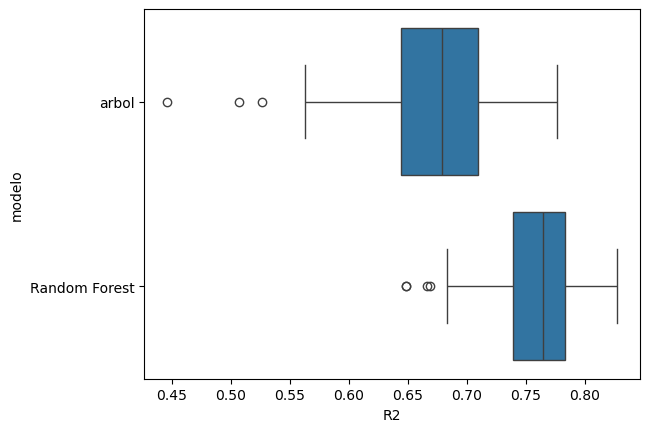

In [71]:
import seaborn as sns

sns.boxplot(data = errores, y = 'modelo', x = 'R2')

<Axes: xlabel='MAPE', ylabel='modelo'>

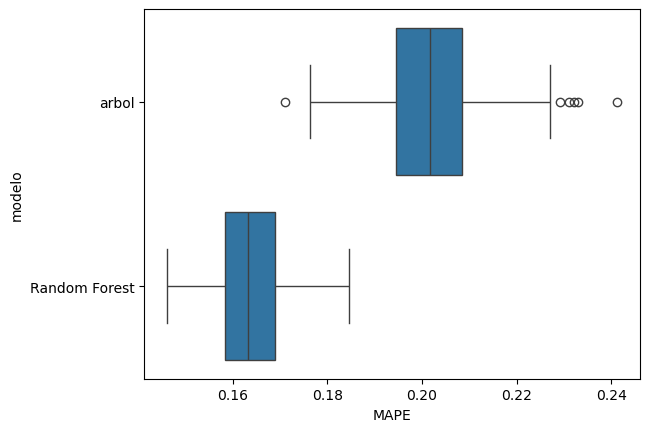

In [73]:
sns.boxplot(data = errores, y = 'modelo', x = 'MAPE')

<Axes: xlabel='MAE', ylabel='modelo'>

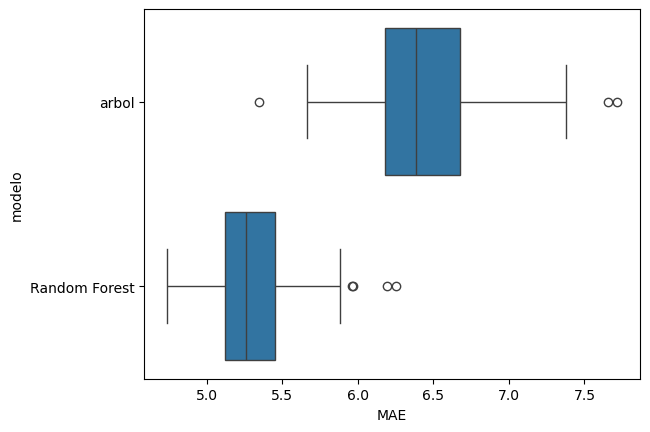

In [75]:
sns.boxplot(data = errores, y = 'modelo', x = 'MAE')

<Axes: >

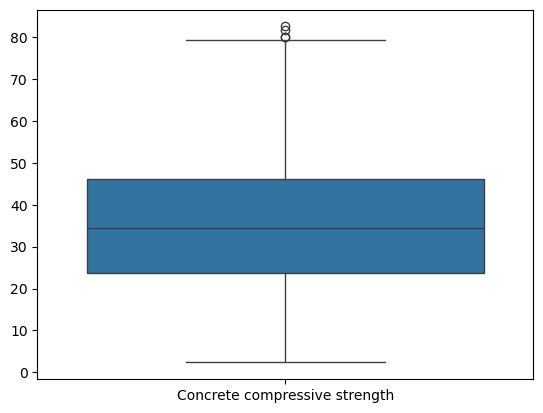

In [77]:
import seaborn as sns

sns.boxplot(y)

noise = np.array(np.random.normal(size=len(y), loc=1, scale=0.5))
- np.random.normal(size=len(y), loc=1, scale=0.5): Esta línea genera una secuencia de números aleatorios con una distribución normal (o gaussiana). Los parámetros de la función son:

Los parametros: 
- size=len(y): Se generan tantos números aleatorios como la longitud de y.
- loc=1: La media de la distribución normal es 1.
- scale=0.5: El desvío estándar de la distribución normal es 0.5.


El resultado:
- El resultado es un array llamado noise que contiene números aleatorios alrededor de 1, con una variación de 0.5, lo que introduce un "ruido" en los datos.
- np.array(...): Convierte la lista generada en un array de NumPy para realizar operaciones vectorizadas más fácilmente.




y2 = []
for i in range(len(y)):
    y2.append(np.array(y)[i] * noise[i])

Aquí se crea una nueva lista y2 donde se almacenarán los nuevos valores de y con ruido añadido.

El ciclo for itera sobre cada índice i de y, y en cada iteración:
- Se accede al elemento i de y con np.array(y)[i] (convirtiendo y en un array por si no lo era previamente).
- Se multiplica este valor por el correspondiente valor en noise[i].
- El resultado se añade a la lista y2 usando append().

Este proceso agrega ruido multiplicativo a cada valor de y, es decir, modifica cada valor de y al multiplicarlo por un valor cercano a 1 (con la variación impuesta por el ruido)

**


Rm:**en:

Este código genera un nuevo conjunto de datos y2 basado en los valores originales de y, aplicando un ruido gaussiano a cada valor. El ruido se genera con una distribución normal de media 1 y desviación estándar 0.5, y el resultado final es un DataFrame que contiene estos valores ruidosos.

In [81]:
import numpy as np

noise = np.array(np.random.normal(size = len(y), loc = 1, scale = 0.5))

y2 = []
for i in range(len(y)):
    y2.append(np.array(y)[i] * noise[i])

y2 = pd.DataFrame(y2)

In [83]:
y2.head()

,0
0,81.993807
1,79.894165
2,35.363707
3,60.740635
4,47.184195


In [85]:
y.shape

(1030, 1)

<Axes: >

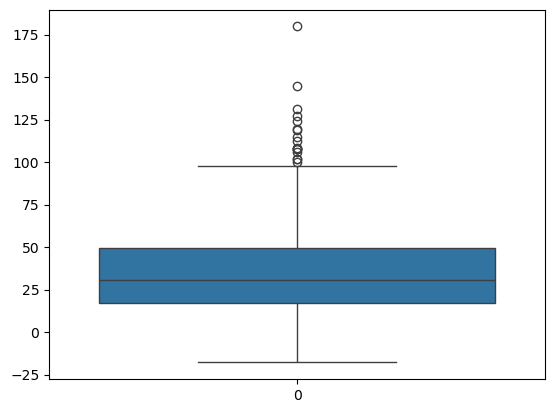

In [87]:
# Se realizo el y2 para ver como se estan distrubuyendo los datos pero con mas ruido.

sns.boxplot(y2)

In [89]:
Ns = 100

r2s = []
mapes = []
maes = []
for i in range(Ns):
    X_train, x_test, y_train, y_test = train_test_split(X, y2, test_size = 0.25)
    reg_tree = DecisionTreeRegressor(max_depth = 5)
    reg_tree.fit(X_train, y_train)

    y_pred = reg_tree.predict(x_test)

    r2s.append(r2_score(y_pred, y_test))
    mapes.append(mean_absolute_percentage_error(y_pred, y_test))
    maes.append(mean_absolute_error(y_pred, y_test))

In [91]:
warnings.filterwarnings('ignore')

Ns = 100

r2s_rf = []
mapes_rf = []
maes_rf = []
for i in range(Ns):
    X_train, x_test, y_train, y_test = train_test_split(X, y2, test_size = 0.25)
    reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
    reg_tree.fit(X_train, y_train)

    y_pred = reg_tree.predict(x_test)

    r2s_rf.append(r2_score(y_pred, y_test))
    mapes_rf.append(mean_absolute_percentage_error(y_pred, y_test))
    maes_rf.append(mean_absolute_error(y_pred, y_test))

In [93]:
arbol = pd.DataFrame({'R2': r2s, 'MAPE': mapes, 'MAE': maes})
arbol['modelo'] = 'arbol'
rfore = pd.DataFrame({'R2': r2s_rf, 'MAPE': mapes_rf, 'MAE': maes_rf})
rfore['modelo'] = 'Random Forest'

errores = pd.concat([arbol, rfore], axis = 0)

In [101]:
sns.set(style="whitegrid")

<Axes: xlabel='R2', ylabel='modelo'>

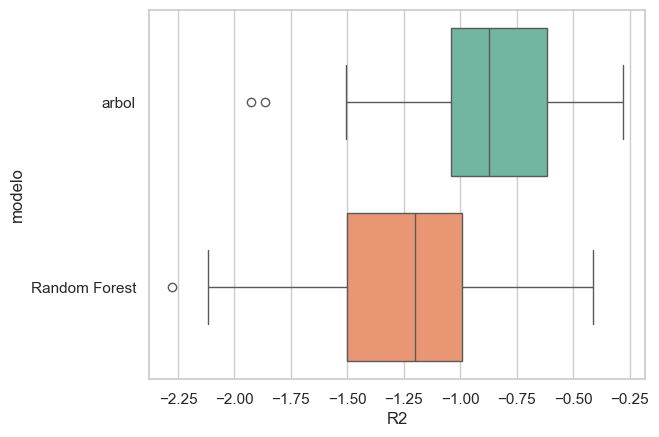

In [103]:
sns.boxplot(data = errores, y = 'modelo', x = 'R2', palette="Set2")

<Axes: xlabel='MAPE', ylabel='modelo'>

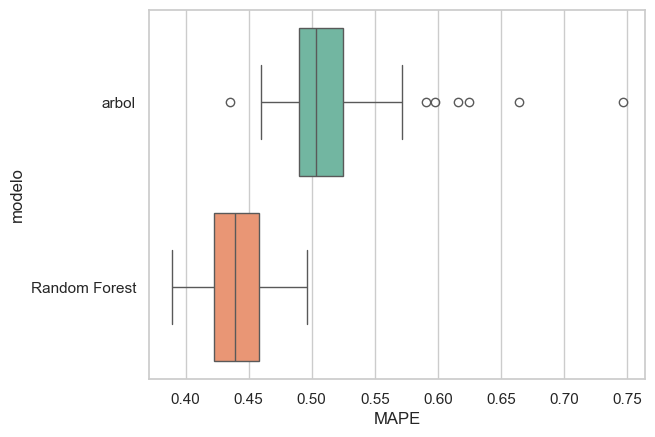

In [107]:
sns.boxplot(data = errores, y = 'modelo', x = 'MAPE', palette="Set2")

El arbol en este caso tiene mucho mas variabilidad que el Random Forest.

<Axes: xlabel='MAE', ylabel='modelo'>

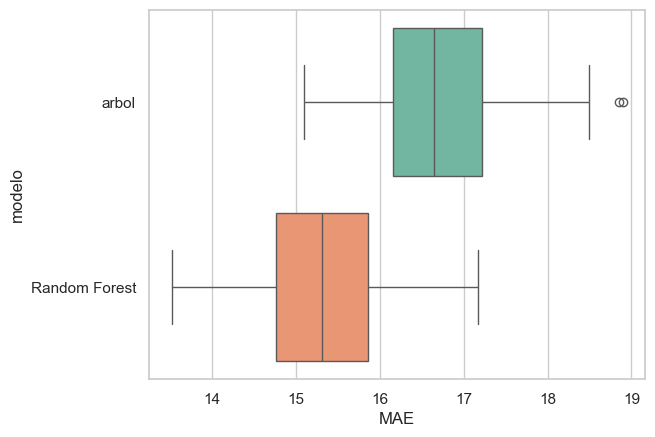

In [109]:
sns.boxplot(data = errores, y = 'modelo', x = 'MAE', palette="Set2")

En el MAE se presentan tambien mayor variabilidad en el arbol que en el de Random Forest. 

En en el Random Forest se presenta una mayor consistencia.

#### Ventajas
- Por el cual, el Random Forest te da un mejor resultado que un Bagging y un Asembling
- Te da resultados mas consistentes




#### Otro punto importante es que Random Forest permite conocer importancia de características para las variables que utilizamos

El arbol como se construye con Bagging, con muchos estimadores, uno puede sacar la importancia de caracteristicas para ese modelo Random Forest.
- El proceso de algoritmo es bien sencillo: entrenar un modelo, sacar una variable y ver cuanto vario el error

In [111]:
X_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.25)
reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
reg_tree.fit(X_train, y_train)

y_pred = reg_tree.predict(x_test)

r2s_rf.append(r2_score(y_pred, y_test))
mapes_rf.append(mean_absolute_percentage_error(y_pred, y_test))
maes_rf.append(mean_absolute_error(y_pred, y_test))

In [113]:
importances = reg_tree.feature_importances_
feature_names = X.columns
forest_importances = pd.Series(importances, index=feature_names)
forest_importances

Cement                0.344748
Blast Furnace Slag    0.070193
Fly Ash               0.011746
Water                 0.084389
Superplasticizer      0.084229
Coarse Aggregate      0.009497
Fine Aggregate        0.018380
Age                   0.376817
dtype: float64

- A diferencia de la regresion, las variables idependientes no te van explicar el modelo.
- Solamente entre mas alto mejor

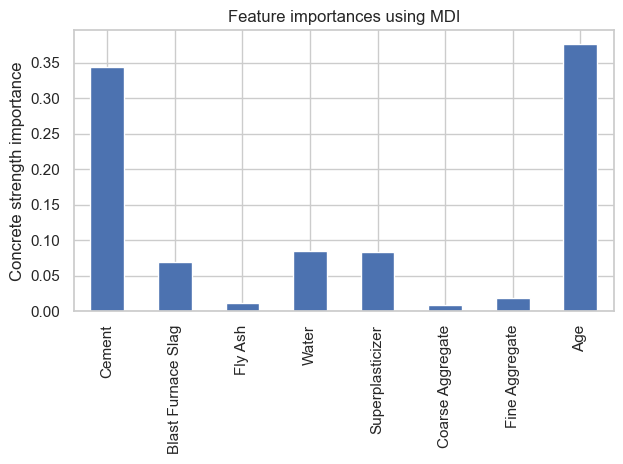

In [115]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
forest_importances.plot.bar(ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Concrete strength importance")
fig.tight_layout()

##### Las 2 variables mas importantes:
- Cement
- Age

##### Las 3 variables menos importantes:
- Fly Ash
- Coarse Aggregate
- Fine Aggregate

Para qué sirve la importancia ?

Entrenemos un modelo con todas las variables y luego uno considerando solo aquellas variables que tienen más importancia en el gráfico anterior

In [117]:
reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
reg_tree.fit(X_train, y_train)

y_pred = reg_tree.predict(x_test)

print('R2 Score', (r2_score(y_pred, y_test)))
print('MAPE', (mean_absolute_percentage_error(y_pred, y_test)))
print('MAE', (mean_absolute_error(y_pred, y_test)))

R2 Score 0.7444718986107988
MAPE 0.15722334630520837
MAE 5.259330269548031


Saquemos las variables poco importantes, las cuales vienen a ser:
- Fly Ash
- Coarse Aggregate
- Fine Aggregate

In [119]:
X_train.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
267,212.0,0.0,124.8,159.0,7.8,1085.4,799.5,56
838,159.0,149.0,116.0,175.0,15.0,953.0,720.0,28
197,194.7,0.0,100.5,165.6,7.5,1006.4,905.9,56
407,165.0,128.5,132.1,175.1,8.1,1005.8,746.6,3
151,401.8,94.7,0.0,147.4,11.4,946.8,852.1,56


Vamos a retirar las variables menos importantes:
- Fly Ash
- Coarse Aggregate
- Fine Aggregate

In [121]:
X_train_2 = X_train[['Cement', 'Age', 'Blast Furnace Slag', 'Water' ,'Superplasticizer']]
X_test_2  = x_test[['Cement', 'Age', 'Blast Furnace Slag', 'Water' ,'Superplasticizer']]

reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
reg_tree.fit(X_train_2, y_train)

y_pred = reg_tree.predict(X_test_2)

print('R2 Score', (r2_score(y_pred, y_test)))
print('MAPE', (mean_absolute_percentage_error(y_pred, y_test)))
print('MAE', (mean_absolute_error(y_pred, y_test)))

R2 Score 0.7413604275546694
MAPE 0.15904667941184952
MAE 5.286621572677345


##### Supongamos que ahora sacamos la variable importante, la cual es Cement

In [123]:
X_train.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
267,212.0,0.0,124.8,159.0,7.8,1085.4,799.5,56
838,159.0,149.0,116.0,175.0,15.0,953.0,720.0,28
197,194.7,0.0,100.5,165.6,7.5,1006.4,905.9,56
407,165.0,128.5,132.1,175.1,8.1,1005.8,746.6,3
151,401.8,94.7,0.0,147.4,11.4,946.8,852.1,56


In [125]:
X_train_3 = X_train[['Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']]
X_test_3  = x_test[['Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']]

reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
reg_tree.fit(X_train_3, y_train)

y_pred = reg_tree.predict(X_test_3)

print('R2 Score', (r2_score(y_pred, y_test)))
print('MAPE', (mean_absolute_percentage_error(y_pred, y_test)))
print('MAE', (mean_absolute_error(y_pred, y_test)))

R2 Score 0.548804888345064
MAPE 0.18641795770716127
MAE 6.354200137710838


Si vemos el R2 Score disminuye considerablemente debido a que Cement viene a ser de las variables mas importantes junto con Age

##### Supongamos que ahora sacamos la otra variable importante, la cual es Age

In [127]:
X_train_3 = X_train[['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate']]
X_test_3  = x_test[['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate']]

reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
reg_tree.fit(X_train_3, y_train)

y_pred = reg_tree.predict(X_test_3)

print('R2 Score', (r2_score(y_pred, y_test)))
print('MAPE', (mean_absolute_percentage_error(y_pred, y_test)))
print('MAE', (mean_absolute_error(y_pred, y_test)))

R2 Score 0.09861638383508609
MAPE 0.2616495544096983
MAE 8.903882528563669


##### Supongamos que ahora solamente utilizamos las variables mas relevantes que son Cement y Age

In [129]:
X_train_3 = X_train[['Cement', 'Age']]
X_test_3  = x_test[['Cement', 'Age']]

reg_tree = RandomForestRegressor(n_estimators = 100, max_depth = 5)
reg_tree.fit(X_train_3, y_train)

y_pred = reg_tree.predict(X_test_3)

print('R2 Score', (r2_score(y_pred, y_test)))
print('MAPE', (mean_absolute_percentage_error(y_pred, y_test)))
print('MAE', (mean_absolute_error(y_pred, y_test)))

R2 Score 0.47118322700418014
MAPE 0.23183693544680287
MAE 7.78042004910749


#### Problema de clasificación

In [131]:
# fetch dataset 
early_stage_diabetes_risk_prediction = fetch_ucirepo(id=529) 
  
# data (as pandas dataframes) 
X = early_stage_diabetes_risk_prediction.data.features 
y = early_stage_diabetes_risk_prediction.data.targets

In [147]:
X

,age,gender,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush,visual_blurring,itching,irritability,delayed_healing,partial_paresis,muscle_stiffness,alopecia,obesity
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,Female,Yes,Yes,Yes,No,Yes,No,No,Yes,No,Yes,Yes,No,No,No
516,48,Female,Yes,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,No,No,No
517,58,Female,Yes,Yes,Yes,Yes,Yes,No,Yes,No,No,No,Yes,Yes,No,Yes
518,32,Female,No,No,No,Yes,No,No,Yes,Yes,No,Yes,No,No,Yes,No


In [135]:
y

,class
0,Positive
1,Positive
2,Positive
3,Positive
4,Positive
...,...
515,Positive
516,Positive
517,Positive
518,Negative


Podemos ver que al ser la mayoria de variables un si o no, realizarlo por arbol de decision es una muy buena opcion

In [137]:
y.value_counts()

class   
Positive    320
Negative    200
Name: count, dtype: int64

In [139]:
y = np.where(y == 'Positive', 1, 0)

In [143]:
y

array([[1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
    

In [145]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   age                 520 non-null    int64 
 1   gender              520 non-null    object
 2   polyuria            520 non-null    object
 3   polydipsia          520 non-null    object
 4   sudden_weight_loss  520 non-null    object
 5   weakness            520 non-null    object
 6   polyphagia          520 non-null    object
 7   genital_thrush      520 non-null    object
 8   visual_blurring     520 non-null    object
 9   itching             520 non-null    object
 10  irritability        520 non-null    object
 11  delayed_healing     520 non-null    object
 12  partial_paresis     520 non-null    object
 13  muscle_stiffness    520 non-null    object
 14  alopecia            520 non-null    object
 15  obesity             520 non-null    object
dtypes: int64(1), object(15)
me

#### Procedemos a binarizar las variables categoricas, con el fin de poder evaluarlos posteriormente.

Por lo cual, seleccionamos la variables categoricas para binarizarlas y despues unirlas nuevamente con las variables continuas

In [149]:
X.select_dtypes(['object']).head()

,gender,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush,visual_blurring,itching,irritability,delayed_healing,partial_paresis,muscle_stiffness,alopecia,obesity
0,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes
1,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No
2,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No
3,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No
4,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes


In [151]:
# dtype es bien importante porque te lo van a poner entero, puedes ponerlo como float o boolean tambien

df_dummy = pd.get_dummies(X.select_dtypes(['object']), drop_first = True, dtype = int)
df_dummy.head(5)

,gender_Male,polyuria_Yes,polydipsia_Yes,sudden_weight_loss_Yes,weakness_Yes,polyphagia_Yes,genital_thrush_Yes,visual_blurring_Yes,itching_Yes,irritability_Yes,delayed_healing_Yes,partial_paresis_Yes,muscle_stiffness_Yes,alopecia_Yes,obesity_Yes
0,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1
1,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0
2,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0
3,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0
4,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1


In [153]:
df = pd.concat([X['age'], df_dummy], axis = 1)
df

,age,gender_Male,polyuria_Yes,polydipsia_Yes,sudden_weight_loss_Yes,weakness_Yes,polyphagia_Yes,genital_thrush_Yes,visual_blurring_Yes,itching_Yes,irritability_Yes,delayed_healing_Yes,partial_paresis_Yes,muscle_stiffness_Yes,alopecia_Yes,obesity_Yes
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,0,1,1,1,0,1,0,0,1,0,1,1,0,0,0
516,48,0,1,1,1,1,1,0,0,1,1,1,1,0,0,0
517,58,0,1,1,1,1,1,0,1,0,0,0,1,1,0,1
518,32,0,0,0,0,1,0,0,1,1,0,1,0,0,1,0


In [155]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

X_train, x_test, y_train, y_test = train_test_split(df, y, test_size = 0.3, random_state = 1234)

tree_cl = DecisionTreeClassifier()

grid_search = GridSearchCV(tree_cl,
                           {'max_depth': [5, 10, 15, 20, 25],
                            'min_samples_split': [0.01, 0.02, 0.03, 0.04]}, 
                           n_jobs=10, 
                           cv = 5)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=10,
             param_grid={'max_depth': [5, 10, 15, 20, 25],
                         'min_samples_split': [0.01, 0.02, 0.03, 0.04]})

In [157]:
grid_search.best_estimator_

DecisionTreeClassifier(max_depth=15, min_samples_split=0.01)

In [159]:
from sklearn.metrics import confusion_matrix

y_pred = grid_search.predict(x_test)

confusion_matrix(y_pred, y_test)

array([[49,  2],
       [ 6, 99]], dtype=int64)

#### Respecto al resultado: 
- Predice 49 verdaderos positivos bien
- Predice 99 de los verdaderos negativos bien
- Solamente se equivoca en 8 casos.


In [161]:
from sklearn.metrics import f1_score, accuracy_score

print('Accuracy: ', accuracy_score(y_pred, y_test))
print('F1 Score: ', f1_score(y_pred, y_test))

Accuracy:  0.9487179487179487
F1 Score:  0.9611650485436893


El resultado del modelo es muy bueno debido a que la mayoria de los datos son categoricos de 2 variables, lo cual al usar el metodo DecisionTreeClassifier se obtiene un buen resultado.

In [163]:
# Recordar lo siguiente:
# Recordar que y no estaba correctamente balanceado

y

array([[1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
    

In [165]:
# Vamos a ver las frecuencias de los datos:

valores, frecuencias = np.unique(y, return_counts=True)

print(dict(zip(valores, frecuencias)))

{0: 200, 1: 320}


Si vemos tenemos una mayor proporcion de datos 1, los cuales eran positivos, que los de 0, los cuales eran negativos anteriormente. Por lo cual, podemos aplicar Smote para equilibrar los datos.

#### Aplicación de Smote

In [167]:
from imblearn.over_sampling import SMOTE

oversample = SMOTE()
df_smote, y_smote = oversample.fit_resample(df, y)

Lo que va hacer SMOTE es colocar datos sinteticos

In [169]:
# Vamos a ver las frecuencias de los datos:

valores, frecuencias = np.unique(y_smote, return_counts=True)

print(dict(zip(valores, frecuencias)))

{0: 320, 1: 320}


In [171]:
pd.DataFrame(y_smote).value_counts()

0
0    320
1    320
Name: count, dtype: int64

In [173]:
rf_clf = RandomForestClassifier()

grid_search = GridSearchCV(rf_clf,
                           {'n_estimators': [200], # el numero de arboles es 200
                            'max_depth': [5, 10, 15, 20, 25],
                            'min_samples_split': [0.001, 0.01, 0.02, 0.03, 0.04]}, 
                           n_jobs=10, # Cantidad de núcleos para el trabajo en paralelo
                           cv = 5)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=10,
             param_grid={'max_depth': [5, 10, 15, 20, 25],
                         'min_samples_split': [0.001, 0.01, 0.02, 0.03, 0.04],
                         'n_estimators': [200]})

In [175]:
grid_search.best_estimator_

RandomForestClassifier(max_depth=20, min_samples_split=0.01, n_estimators=200)

In [177]:
y_pred = grid_search.predict(x_test)

confusion_matrix(y_pred, y_test)

array([[ 50,   0],
       [  5, 101]], dtype=int64)

#### Resultado anterior: 
- Predice 49 verdaderos positivos bien
- Predice 99 de los verdaderos negativos bien
- Solamente se equivoca en 8 casos.


#### Resultado nuevo: 
- Predice 50 verdaderos positivos bien
- Predice 101 de los verdaderos negativos bien
- Solamente se equivoco en 5 casos.

#### Anterior resultado:

- Accuracy:  0.9487179487179487- 
F1 Score:  0.9611650485436893


In [180]:
# Resultado nuevo

print('Accuracy', accuracy_score(y_pred, y_test))
print('F1 Score', f1_score(y_pred, y_test))

Accuracy 0.967948717948718
F1 Score 0.9758454106280193


#### De escoger ambos modelos, me quedo con el resultado nuevo, es decir con Random Forest.

- Me quedo con Random Forest debido a que tengo menos riesgo de sobre ajuste.
- El random forest se sobre ajusta menos que los arboles de decision

#### Ensembling

Puedes tomar muchos modelos y juntarlos en 1 solo.

In [182]:
from sklearn.ensemble import BaggingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier

In [184]:
# Construyes las instancias de los modelos.

tree  = DecisionTreeClassifier(max_depth = 50, min_samples_leaf=10)
SVM_1 = SVC(kernel='rbf')
SVM_2 = SVC(kernel='sigmoid')
lr    = LogisticRegression()

In [186]:
estimators = []
estimators.append(('Decision Tree', tree))
estimators.append(('Support Vector Machine 1', SVM_1))
estimators.append(('Support Vector Machine 2', SVM_2))
estimators.append(('Logistic Regression', lr))
estimators

[('Decision Tree', DecisionTreeClassifier(max_depth=50, min_samples_leaf=10)),
 ('Support Vector Machine 1', SVC()),
 ('Support Vector Machine 2', SVC(kernel='sigmoid')),
 ('Logistic Regression', LogisticRegression())]

In [188]:
SC = StackingClassifier(estimators=estimators,cv=5)
SC.fit(X_train, y_train)

StackingClassifier(cv=5,
                   estimators=[('Decision Tree',
                                DecisionTreeClassifier(max_depth=50,
                                                       min_samples_leaf=10)),
                               ('Support Vector Machine 1', SVC()),
                               ('Support Vector Machine 2',
                                SVC(kernel='sigmoid')),
                               ('Logistic Regression', LogisticRegression())])

In [190]:
y_pred = SC.predict(x_test)

In [192]:
confusion_matrix(y_pred, y_test)

array([[45,  3],
       [10, 98]], dtype=int64)

In [194]:
print('Accuracy', accuracy_score(y_pred, y_test))
print('F1 Score', f1_score(y_pred, y_test))

Accuracy 0.9166666666666666
F1 Score 0.937799043062201


In [196]:
from sklearn.metrics import classification_report

classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.94      0.82      0.87        55\n           1       0.91      0.97      0.94       101\n\n    accuracy                           0.92       156\n   macro avg       0.92      0.89      0.91       156\nweighted avg       0.92      0.92      0.92       156\n'